# Chapter 2: Data and Sampling Distributions
**Referensi:** *Practical Statistics for Data Scientists (O'Reilly)*

Di era Big Data, teknik penarikan sampel (*sampling*) tetap menjadi alat yang sangat penting bagi Data Scientist. Kualitas data jauh lebih berharga daripada kuantitas data.

---

## 1. Random Sampling & Sample Bias

### Konsep Utama:
1. **Populasi ($N$) vs. Sampel ($n$):**
   * **Populasi ($N$):** Keseluruhan himpunan data atau entitas teoritis yang ingin dianalisis.
   * **Sampel ($n$):** Subhimpunan (*subset*) yang diambil dari populasi untuk dianalisis secara langsung.
2. **Random Sampling (Penarikan Sampel Acak):**
   Prosedur pengambilan anggota dari populasi di mana setiap elemen memiliki peluang yang sama untuk terpilih. Bertujuan untuk menghasilkan sampel yang *representatif* dan bebas dari bias.
3. **Sample Bias (Bias Sampel):**
   Terjadi ketika pengamatan atau pengukuran acap kali salah secara sistematis karena sampel tidak mewakili populasi asli secara utuh.
4. **Selection Bias & Regression to the Mean:**
   * **Selection Bias:** Terjadi akibat metode pemilihan data yang secara tidak sadar memfavoritkan karakteristik tertentu.
   * **Regression to the Mean:** Fenomena statistik di mana nilai pengukuran ekstrem cenderung diikuti oleh nilai yang lebih mendekati rata-rata populasi pada pengukuran berikutnya.

=== STATISTIK POPULASI ===
Jumlah Populasi (N)  : 50,000
Mean Populasi (μ)   : $68,760.52
Std Dev Populasi (σ): $32,872.04

=== PERBANDINGAN RATA-RATA SAMPEL (Sample Mean vs Population Mean) ===
Sample Mean (n=10)   : $78,830.00 | Selisih: $10,069.48
Sample Mean (n=100)  : $73,939.86 | Selisih: $5,179.34
Sample Mean (n=1000) : $68,804.10 | Selisih: $43.58


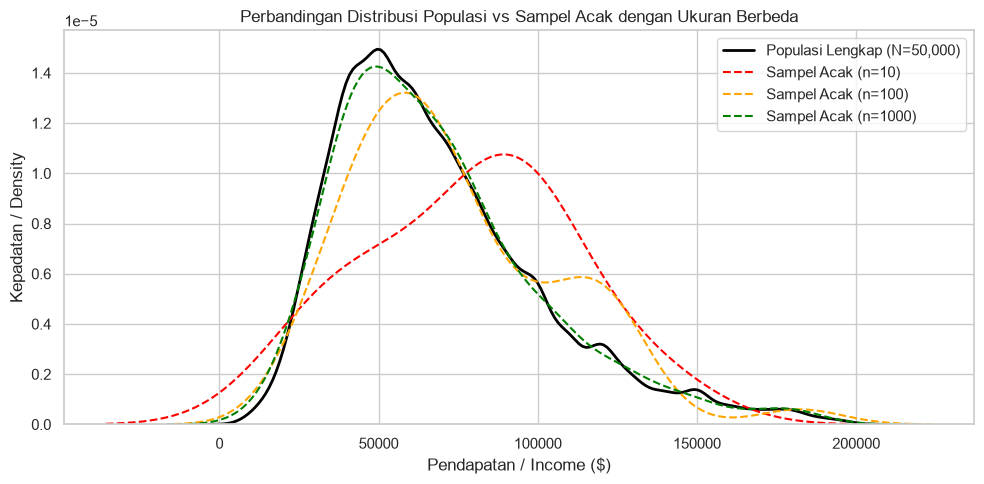

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set seed untuk reproduksibilitas hasil
np.random.seed(42)

# 1. Memuat dataset loans_income.csv (mewakili Populasi pendapatan peminjam)
loans_income = pd.read_csv('data/loans_income.csv').squeeze('columns')

print("=== STATISTIK POPULASI ===")
print(f"Jumlah Populasi (N)  : {len(loans_income):,}")
print(f"Mean Populasi (μ)   : ${loans_income.mean():,.2f}")
print(f"Std Dev Populasi (σ): ${loans_income.std():,.2f}\n")

# 2. Simulasi Random Sampling dengan ukuran sampel (n) berbeda
samples_n10 = loans_income.sample(n=10)
samples_n100 = loans_income.sample(n=100)
samples_n1000 = loans_income.sample(n=1000)

print("=== PERBANDINGAN RATA-RATA SAMPEL (Sample Mean vs Population Mean) ===")
print(f"Sample Mean (n=10)   : ${samples_n10.mean():,.2f} | Selisih: ${abs(samples_n10.mean() - loans_income.mean()):,.2f}")
print(f"Sample Mean (n=100)  : ${samples_n100.mean():,.2f} | Selisih: ${abs(samples_n100.mean() - loans_income.mean()):,.2f}")
print(f"Sample Mean (n=1000) : ${samples_n1000.mean():,.2f} | Selisih: ${abs(samples_n1000.mean() - loans_income.mean()):,.2f}")

# 3. Visualisasi Pengaruh Ukuran Sampel terhadap Distribusi Sampel
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))

sns.kdeplot(loans_income, label='Populasi Lengkap (N=50,000)', color='black', linewidth=2)
sns.kdeplot(samples_n10, label='Sampel Acak (n=10)', color='red', linestyle='--')
sns.kdeplot(samples_n100, label='Sampel Acak (n=100)', color='orange', linestyle='--')
sns.kdeplot(samples_n1000, label='Sampel Acak (n=1000)', color='green', linestyle='--')

plt.title('Perbandingan Distribusi Populasi vs Sampel Acak dengan Ukuran Berbeda')
plt.xlabel('Pendapatan / Income ($)')
plt.ylabel('Kepadatan / Density')
plt.legend()
plt.tight_layout()
plt.show()

### Analisis & Kesimpulan Bagian 1:

1. **Pengaruh Ukuran Sampel ($n$) terhadap Akurasi Estimasi:**
   Semakin besar ukuran sampel ($n$), rata-rata sampel (*Sample Mean* / $\bar{x}$) akan semakin presisi mendekati rata-rata populasi (*Population Mean* / $\mu$). Selisih antara statistik sampel dan parameter populasi menurun secara signifikan seiring bertambahnya $n$.

2. **Representasi Bentuk Distribusi:**
   Grafik *Density Plot* menunjukkan bahwa sampel berukuran kecil ($n=10$) memiliki variabilitas tinggi dan bentuk yang belum stabil. Sebaliknya, sampel $n=1.000$ sudah dapat menirukan bentuk distribusi asli populasi secara sangat akurat.

3. **Relevansi untuk Data Science:**
   Kualitas sampel jauh lebih penting daripada sekadar ukuran data yang besar. Mengambil *random sample* yang representatif terbukti efektif untuk eksplorasi dan eksperimen model tanpa memerlukan beban komputasi dari seluruh populasi.

---

## 2. Sampling Distributions, Central Limit Theorem (CLT) & Standard Error

Memahami perbedaan antara distribusi data mentah dan distribusi statistik sampel merupakan konsep fundamental dalam inferensi statistik.

### Konsep Kunci:

1. **Data Distribution vs. Sampling Distribution:**
   * **Data Distribution:** Distribusi frekuensi dari nilai-nilai individu dalam suatu dataset populasi atau sampel.
   * **Sampling Distribution:** Distribusi probabilitas dari suatu **statistik sampel** (misalnya rata-rata sampel / *sample mean*) yang diperoleh dari penarikan berulang banyak sampel acak dengan ukuran $n$ yang sama dari populasi.

2. **Central Limit Theorem / CLT (Teorema Limit Pusat):**
   * Menyatakan bahwa distribusi dari rata-rata sampel ($\bar{x}$) akan cenderung mendekati **Distribusi Normal** (berbentuk kurva lonceng) seiring bertambahnya ukuran sampel ($n$), **meskipun** distribusi populasi aslinya tidak berdistribusi normal (misalnya *skewed* atau *bimodal*).
   * Fenomena ini memungkinkan pemodelan statistik dilakukan tanpa harus bergantung pada asumsi ketat mengenai bentuk populasi asal.

3. **Standard Error / SE (Galat Standar):**
   * Ukuran variabilitas atau penyebaran dari suatu statistik sampel di antara sampel-sampel yang ditarik berulang.
   * Berbeda dengan *Standard Deviation* ($s$) yang mengukur variabilitas data individu, *Standard Error* ($SE$) mengukur ketidakpastian/variabilitas dari estimasi sampel.
   
   $$\text{SE} = \frac{s}{\sqrt{n}}$$

   *(di mana $s$ adalah deviasi standar sampel dan $n$ adalah ukuran sampel).*

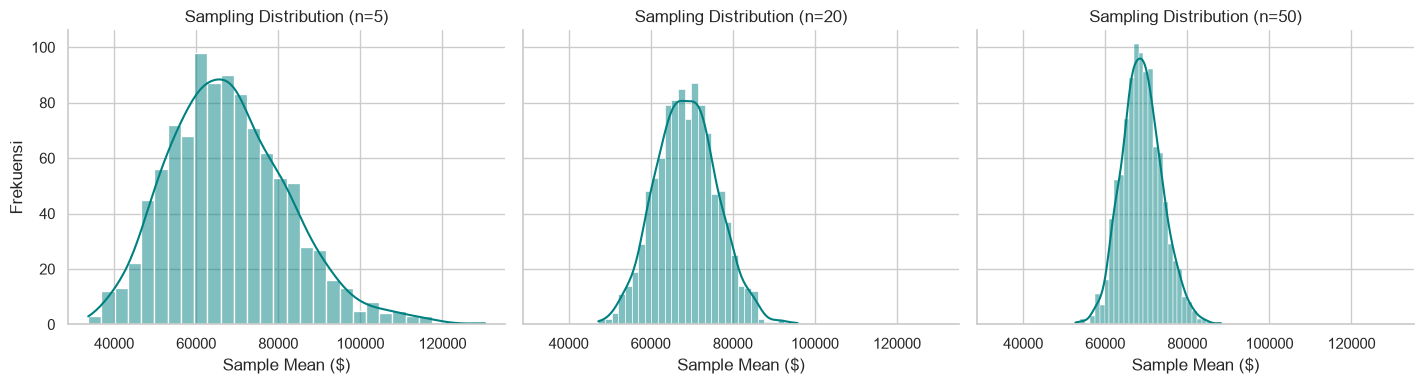

=== PERBANDINGAN STANDARD ERROR (SE) ===
Ukuran Sampel n= 5 | Empirical SE: $14,621.25 | Theoretical SE: $14,700.82
Ukuran Sampel n=20 | Empirical SE: $7,441.24 | Theoretical SE: $7,350.41
Ukuran Sampel n=50 | Empirical SE: $4,918.70 | Theoretical SE: $4,648.81


In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Memuat dataset loans_income.csv
loans_income = pd.read_csv('data/loans_income.csv').squeeze('columns')

# 1. Simulasi pembentukan Sampling Distribution dari Mean
# Mengambil 1.000 sampel acak untuk ukuran n=5, n=20, dan n=50
results = []
for sample_size in [5, 20, 50]:
  sample_means = [
      loans_income.sample(n=sample_size).mean() for _ in range(1000)
  ]
  results.append(
      pd.DataFrame({'mean': sample_means, 'size': f'n={sample_size}'})
  )

results_df = pd.concat(results)

# 2. Visualisasi Demonstrasi Central Limit Theorem (CLT)
sns.set_theme(style='whitegrid')
g = sns.FacetGrid(results_df, col='size', height=4, aspect=1.2)
g.map(sns.histplot, 'mean', kde=True, color='teal', bins=30)
g.set_axis_labels('Sample Mean ($)', 'Frekuensi')
g.set_titles('Sampling Distribution ({col_name})')
plt.tight_layout()
plt.show()

# 3. Perhitungan Empiris vs Teoretis untuk Standard Error (SE)
print('=== PERBANDINGAN STANDARD ERROR (SE) ===')
for sample_size in [5, 20, 50]:
  empirical_se = results_df[results_df['size'] == f'n={sample_size}'][
      'mean'
  ].std()
  theoretical_se = loans_income.std() / np.sqrt(sample_size)
  print(
      f'Ukuran Sampel n={sample_size:2d} | Empirical SE: ${empirical_se:,.2f} |'
      f' Theoretical SE: ${theoretical_se:,.2f}'
  )

### Analisis & Kesimpulan Bagian 2:

1. **Pembuktian Visual Central Limit Theorem (CLT):**
   Meskipun data populasi pendapatan peminjam (`loans_income`) memiliki skewness positif (menceng ke kanan), grafik *Sampling Distribution* memperlihatkan bahwa ketika ukuran sampel dinaikkan ($n=5 \rightarrow n=20 \rightarrow n=50$), distribusi dari *sample mean* semakin simetris dan membentuk kurva lonceng teratur khas Distribusi Normal.

2. **Perilaku Standard Error (SE):**
   * Nilai *Standard Error* menurun secara konsisten seiring bertambahnya ukuran sampel $n$.
   * Nilai *Empirical SE* (hasil simulasi penarikan 1.000 sampel) sangat presisi mendekati *Theoretical SE* berdasarkan rumus $\frac{s}{\sqrt{n}}$.
   * Untuk memperkecil *Standard Error* menjadi setengahnya, ukuran sampel harus dinaikkan sebesar $4 \times$ lipat akibat keberadaan akar kuadrat ($\sqrt{n}$) pada penyebut.

3. **Implikasi bagi Data Scientist:**
   CLT memberi kepastian bahwa estimasi rata-rata yang dihitung dari sampel berukuran cukup besar ($n \ge 30$) memiliki tingkat ketidakpastian yang terukur, sehingga dapat dipercaya sebagai cerminan nilai populasi sebenarnya.

---

## 3. The Bootstrap & Confidence Intervals

Dalam praktik Data Science modern, **Bootstrap** adalah metode resampling yang paling serbaguna untuk mengukur variabilitas dan membuat rentang kepercayaan (*Confidence Intervals*) tanpa harus bergantung pada rumus matematika yang rumit atau asumsi distribusi tertentu.

### Konsep Utama:

1. **The Bootstrap (Resampling dengan Pengembalian):**
   * Prosedur menarik sampel berulang kali dari dataset observasi asli **dengan pengembalian** (*with replacement*).
   * Ukuran setiap sampel bootstrap ($n$) sama persis dengan ukuran dataset asli.
   * Memungkinkan kita membuat ribuan "dataset tiruan" untuk menghitung statistik yang diinginkan (seperti mean, median, atau persentil) dan mengamati distribusinya.

2. **Confidence Intervals / CI (Rentang Kepercayaan):**
   * Cara standar untuk menyajikan estimasi statistik bukan sebagai satu angka tunggal (*point estimate*), melainkan sebagai **rentang nilai** yang dipadukan dengan tingkat kepercayaan tertentu (misalnya 90% atau 95%).
   * **Algoritma Bootstrap Confidence Interval:**
     1. Tarik sampel bootstrap berukuran $n$ dengan pengembalian dari data asli.
     2. Hitung statistik sampel (misalnya median).
     3. Ulangi langkah 1 dan 2 sebanyak $R$ kali (misalnya $R = 10.000$).
     4. Untuk CI 95%, ambil persentil ke-2.5 dan persentil ke-97.5 dari distribusi statistik bootstrap tersebut.

=== STATISTIK BOOTSTRAP MEDIAN (n=20, R=10,000) ===
Median Sampel Asli        : $65,500.00
Rata-rata Median Bootstrap  : $67,799.60
Standard Error Bootstrap  : $11,937.90
95% Confidence Interval    : [$48,000.00 - $91,500.00]
Median Populasi Sebenarnya : $62,000.00


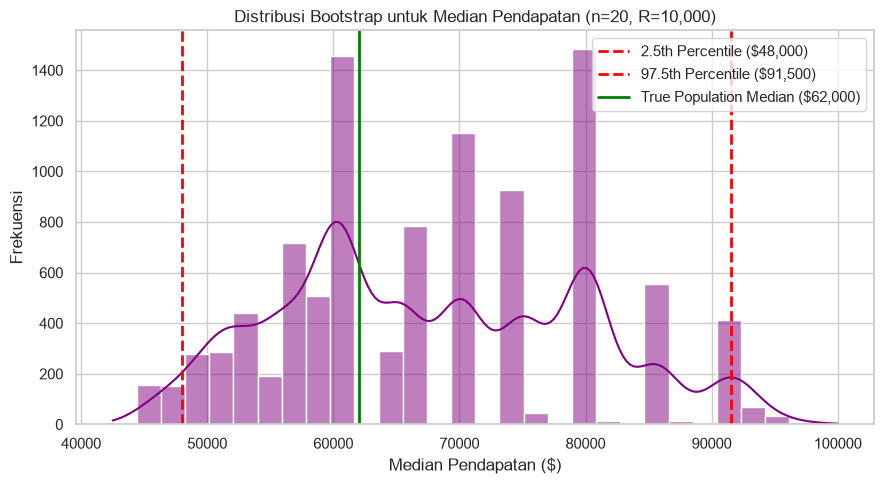

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils import resample

# Memuat dataset loans_income.csv
loans_income = pd.read_csv('data/loans_income.csv').squeeze('columns')

# 1. Mengambil satu sampel acak berukuran n=20 sebagai dataset eksperimen kita
np.random.seed(42)
sample20 = loans_income.sample(n=20)

# 2. Implementasi Algoritma Bootstrap (R = 10.000 iterasi) untuk Median
results = []
for _ in range(10000):
    boot_sample = resample(sample20)
    results.append(boot_sample.median())

results = pd.Series(results)

# 3. Menghitung 95% Confidence Interval (Persentil ke-2.5 dan ke-97.5)
ci_lower = np.percentile(results, 2.5)
ci_upper = np.percentile(results, 97.5)

print("=== STATISTIK BOOTSTRAP MEDIAN (n=20, R=10,000) ===")
print(f"Median Sampel Asli        : ${sample20.median():,.2f}")
print(f"Rata-rata Median Bootstrap  : ${results.mean():,.2f}")
print(f"Standard Error Bootstrap  : ${results.std():,.2f}")
print(f"95% Confidence Interval    : [${ci_lower:,.2f} - ${ci_upper:,.2f}]")
print(f"Median Populasi Sebenarnya : ${loans_income.median():,.2f}")

# 4. Visualisasi Distribusi Bootstrap & Rentang Kepercayaan
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5))

sns.histplot(results, kde=True, color='purple', bins=30)
plt.axvline(ci_lower, color='red', linestyle='--', linewidth=2, label=f'2.5th Percentile (${ci_lower:,.0f})')
plt.axvline(ci_upper, color='red', linestyle='--', linewidth=2, label=f'97.5th Percentile (${ci_upper:,.0f})')
plt.axvline(loans_income.median(), color='green', linestyle='-', linewidth=2, label=f'True Population Median (${loans_income.median():,.0f})')

plt.title('Distribusi Bootstrap untuk Median Pendapatan (n=20, R=10,000)')
plt.xlabel('Median Pendapatan ($)')
plt.ylabel('Frekuensi')
plt.legend()
plt.tight_layout()
plt.show()

### Analisis & Kesimpulan Bagian 3:

1. **Keunggulan Utama Bootstrap:**
   * Berbeda dengan statistik klasik yang membutuhkan rumus matematika rumit untuk menghitung *Standard Error* dari nilai median, **Bootstrap** menyelesaikan masalah ini dengan pendekatan komputasi/simulasi yang intuitif dan fleksibel untuk statistik apa pun.

2. **Interpretasi Confidence Interval:**
   * Berdasarkan sampel berukuran kecil ($n=20$), kita berhasil menghasilkan 95% *Confidence Interval* bootstrap untuk nilai median pendapatan.
   * Nilai median populasi sebenarnya ($\$62.000$) terbukti berada tepat di dalam rentang kepercayaan yang dihasilkan oleh simulasi bootstrap.

3. **Relevansi dalam Pemodelan Data Science:**
   * Konsep *resampling with replacement* pada Bootstrap tidak hanya digunakan untuk menghitung rentang kepercayaan, tetapi juga menjadi fondasi dasar dari algoritma Machine Learning populer seperti **Random Forest** (*Bootstrap Aggregating* / *Bagging*).

---

## 4. Key Statistical Distributions

Meskipun data dalam dunia nyata jarang sekali mengikuti distribusi teoretis yang sempurna, memahami distribusi statistik standar sangat penting karena distribusi ini menjadi asumsi dasar dari banyak model statistik dan algoritma Machine Learning.

### Jenis-Jenis Distribusi Kunci:

1. **Normal Distribution (Distribusi Normal / Gaussian):**
   * Berbentuk kurva lonceng simetris yang ditentukan oleh rata-rata ($\mu$) dan deviasi standar ($\sigma$).
   * **QQ-Plot (Quantile-Quantile Plot):** Alat visual untuk mengevaluasi seberapa dekat distribusi dataset observasi dengan Distribusi Normal teoretis. Jika titik-titik data berada sejajar di sepanjang garis diagonal, maka data tersebut terdistribusi secara normal.

2. **Long-Tailed Distributions:**
   * Distribusi di mana nilai-nilai ekstrem (*outliers*) muncul jauh lebih sering daripada yang diperkirakan oleh Distribusi Normal (memiliki ekor yang tebal).

3. **Student's t-Distribution:**
   * Berbentuk mirip Distribusi Normal tetapi memiliki ekor (*tails*) yang lebih tebal dan puncak yang lebih rendah. Digunakan ketika ukuran sampel kecil atau deviasi standar populasi tidak diketahui.

4. **Binomial Distribution:**
   * Memodelkan jumlah keberhasilan ($k$) dalam $n$ kali percobaan independen (*trials*) dengan probabilitas sukses $p$ pada setiap percobaan (misalnya: eksperimen *A/B Testing* klik/tanpa klik).

5. **Poisson & Exponential Distributions:**
   * **Poisson:** Memodelkan frekuensi jumlah kejadian suatu peristiwa per unit waktu atau ruang (misalnya: jumlah kunjungan website per menit).
   * **Exponential:** Memodelkan waktu tunggu atau interval jarak dari satu kejadian ke kejadian berikutnya.

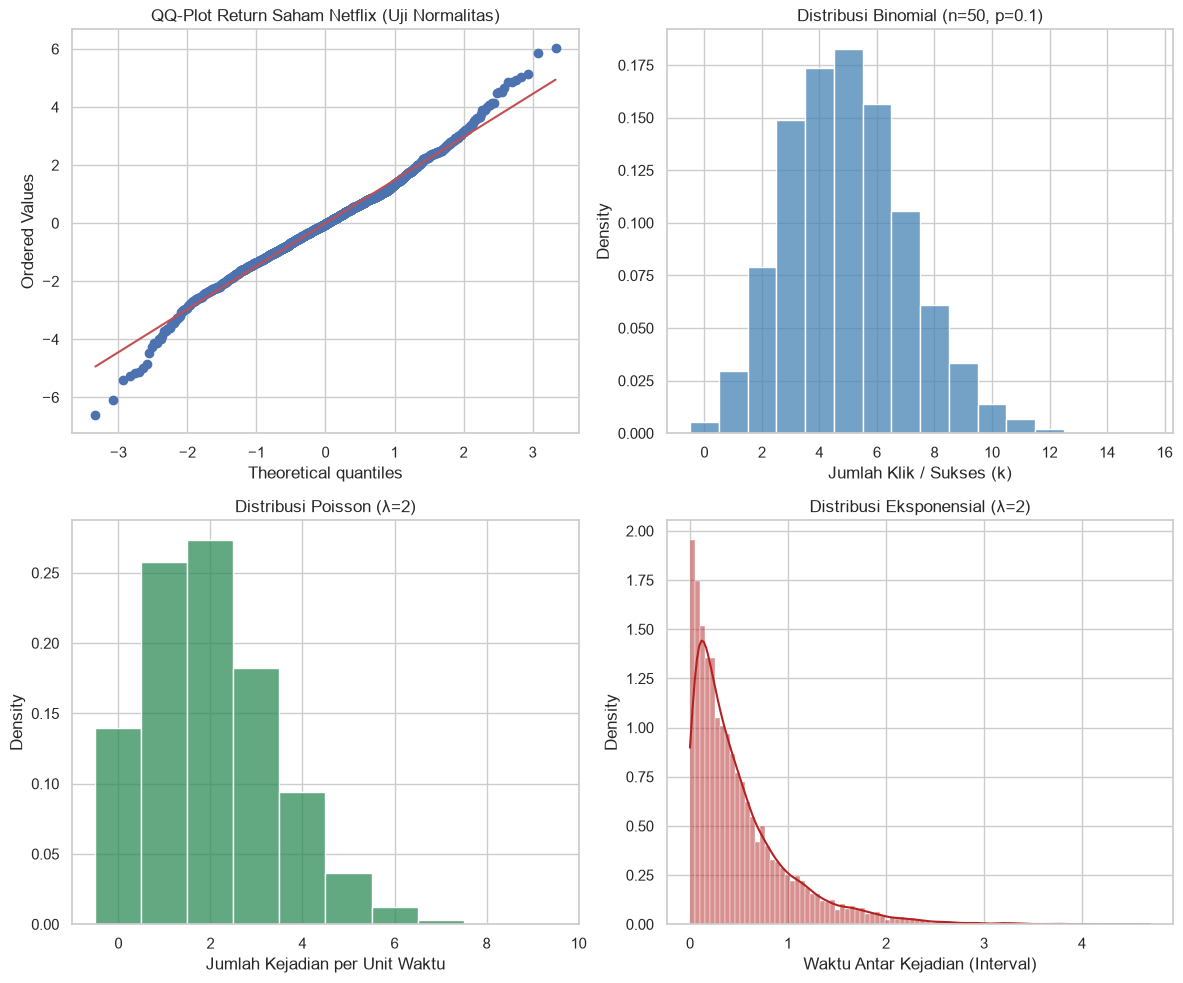

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set style visualisasi
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# 1. Normal Distribution & QQ-Plot (Data Return Saham Netflix / SP500)
sp500_px = pd.read_csv('data/sp500_data.csv.gz', index_col=0)
nflx = sp500_px['NFLX']
nflx_returns = np.diff(np.log(nflx[nflx > 0]))

stats.probplot(nflx_returns, dist="norm", plot=axes[0, 0])
axes[0, 0].set_title('QQ-Plot Return Saham Netflix (Uji Normalitas)')

# 2. Simulasi Binomial Distribution (Eksperimen A/B Testing)
# 10.000 simulasi dengan n=50 percobaan dan p=0.1 (10% CTR)
sample_binom = stats.binom.rvs(n=50, p=0.1, size=10000)
sns.histplot(sample_binom, discrete=True, ax=axes[0, 1], color='steelblue', stat="density")
axes[0, 1].set_title('Distribusi Binomial (n=50, p=0.1)')
axes[0, 1].set_xlabel('Jumlah Klik / Sukses (k)')

# 3. Simulasi Poisson Distribution
# Rata-rata 2 kejadian per menit (lambda = 2)
sample_poisson = stats.poisson.rvs(mu=2, size=10000)
sns.histplot(sample_poisson, discrete=True, ax=axes[1, 0], color='seagreen', stat="density")
axes[1, 0].set_title('Distribusi Poisson (λ=2)')
axes[1, 0].set_xlabel('Jumlah Kejadian per Unit Waktu')

# 4. Simulasi Exponential Distribution
# Waktu antar kejadian dengan lambda = 2 (scale = 1/lambda = 0.5)
sample_exp = stats.expon.rvs(scale=0.5, size=10000)
sns.histplot(sample_exp, kde=True, ax=axes[1, 1], color='firebrick', stat="density")
axes[1, 1].set_title('Distribusi Eksponensial (λ=2)')
axes[1, 1].set_xlabel('Waktu Antar Kejadian (Interval)')

plt.tight_layout()
plt.show()

### Analisis & Kesimpulan Bagian 4:

1. **Interpretasi QQ-Plot pada Data Keuangan:**
   * Grafik QQ-Plot untuk return harian saham Netflix memperlihatkan bahwa titik-titik data melengkung menjauhi garis diagonal di kedua ujung (*tails*).
   * Hal ini membuktikan bahwa data return pasar keuangan bersifat **Long-Tailed**, di mana kejadian ekstrem (*profit* atau *loss* besar) terjadi jauh lebih sering daripada asumsi Distribusi Normal teoretis.

2. **Penerapan Binomial dan Poisson dalam Data Science:**
   * **Binomial Distribution:** Sangat berguna untuk menganalisis hasil eksperimen biner seperti *Click-Through Rate* (CTR) atau konversi pada *A/B Testing*.
   * **Poisson & Exponential Distribution:** Berfungsi memodelkan antrean sistem (*queuing theory*), trafik server/aplikasi, serta memodelkan durasi waktu kegagalan perangkat keras.

---

# Rangkuman Keseluruhan Chapter 2: Data and Sampling Distributions

1. **Random Sampling & Selection Bias:**
   * *Random Sampling* penting untuk memastikan sampel representatif terhadap populasi. Kualitas data dan metode penarikan sampel jauh lebih menentukan keandalan estimasi daripada sekadar besarnya jumlah data.

2. **Central Limit Theorem (CLT) & Standard Error:**
   * CLT menjamin bahwa distribusi rata-rata sampel (*sample mean*) akan mendekati **Distribusi Normal** seiring bertambahnya ukuran sampel ($n$), terlepas dari bentuk distribusi populasi aslinya.
   * **Standard Error (SE)** mengukur variabilitas antar estimasi sampel dan nilainya berbanding terbalik dengan akar ukuran sampel ($\sqrt{n}$).

3. **The Bootstrap & Confidence Intervals:**
   * **Bootstrap** (*resampling with replacement*) adalah teknik komputasi serbaguna untuk memperkirakan *Standard Error* dan membentangkan **Confidence Interval (CI)** tanpa bergantung pada asumsi matematis yang rumit.

4. **Distribusi Statistik Utama:**
   * **Normal & QQ-Plot:** Alat untuk menguji normalitas data.
   * **Binomial:** Memodelkan frekuensi sukses dalam $n$ percobaan biner.
   * **Poisson & Exponential:** Memodelkan frekuensi kejadian berdurasi dan interval waktu tunggu antar kejadian.